# 위고비 시장 확산에 따른 기존 담보 보험금 종합영향

**SELECT 유사 고위험 가상 가입자 1,000명 × 10년 기존 보험계약 조건부 모형**

동일한 집단에서 위고비 시장이 저확산에서 고확산으로 이동할 때 정기 사망, 비치명적 심근경색·뇌졸중, 담낭절제술 보험금의 현재가치가 어떻게 달라지는지 하나의 일별 모형으로 비교한다.

> 결과명은 **위고비 시장 확산에 따른 기존 담보 보험금 현가 변화**다. 기존 계약 보험료, 준비금, 투자손익, 자본비용과 약제비 특약 손익은 포함하지 않는다.

## 1. 왜 기존 세 결과를 바로 더할 수 없는가

01~03번 개별 노트북은 시간축, 시작경로, 할인율과 치료 노출 정의가 달랐다. 특히 담낭 분석은 Safwan RR 2.59를 기준으로 사용했지만, 이번 공통모형은 SELECT 안전성 결과 1.4% 대 1.1%를 기준으로 사용한다. 따라서 기존 숫자를 합산하지 않고 대상·시작·치료·생존·할인을 하나의 일별 체계로 다시 계산한다.

## 2. 실행 환경과 공통 입력

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'config/existing_claims_impact.json').exists():
            return candidate
    raise FileNotFoundError('저장소 루트를 찾지 못했습니다: config/existing_claims_impact.json 필요')

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

font_candidates = [
    Path('/System/Library/Fonts/Supplemental/Arial Unicode.ttf'),
    Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
    Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc'),
]
for font_path in font_candidates:
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=font_path).get_name()
        break
plt.rcParams.update({
    'axes.unicode_minus': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})

BLUE = '#2F6B9A'
LIGHT_BLUE = '#9CC3DF'
ORANGE = '#D96C20'
LIGHT_ORANGE = '#F2AD68'
GREY = '#747C84'

In [2]:
from models.impact.existing_claims import build_analysis, write_analysis

analysis = build_analysis(include_sensitivities=True)
write_analysis(analysis)

config = analysis['config']
base = analysis['base']
claim_df = pd.DataFrame(base['claim_rows'])
exposure_df = pd.DataFrame([
    {
        '시장': '저확산' if market == 'low' else '고확산',
        '10년 최초 시작자': base[market]['total_first_starts'],
        '치료 중 인년': base[market]['treatment_exposure_person_years'],
        '10년 기대 사망': base[market]['total_deaths'],
    }
    for market in ('low', 'high')
])
sens_df = pd.DataFrame(analysis['one_way_sensitivity'])
combined_df = pd.DataFrame(analysis['combined_scenarios'])

display(pd.DataFrame({
    '항목': ['대상', '최초 가입자', '관찰기간', '할인율', '담보 보유율', '기준 노출방식'],
    '기준': [
        config['analysis']['target_population'],
        f"{config['analysis']['initial_cohort']:,.0f}명",
        f"{config['analysis']['term_years']}년",
        f"{config['analysis']['annual_discount_rate']:.2%}",
        '담보별 100%',
        config['analysis']['base_exposure_method'],
    ],
}))

,항목,기준
0,대상,SELECT 유사·비당뇨·위고비 미사용 고위험 가상 가입자
1,최초 가입자,"1,000명"
2,관찰기간,10년
3,할인율,2.75%
4,담보 보유율,담보별 100%
5,기준 노출방식,on_treatment_published


## 3. 공통 대상·상태·담보 가정

전용 시작경로 `existing_market_low/high`는 특약 없음, 선택비 1.0으로 시작률 모형을 다시 실행한다. 최초 시작은 생존·미시작자에게만 적용하고, 재개는 신규 시작으로 세지 않는다.

일별 순서는 **최초 시작 → 치료 지속·중단·재개 → 비치명적 심근경색 → 비치명적 뇌졸중 → 담석증·담낭절제술 → 사망 → 다음 날·할인**이다. 비치명적 사건자는 생존·다른 담보·이후 치료 시작 위험에 남고, 동일 담보는 첫 1회만 지급한다. 같은 날 비치명적 사건과 사망이 순차적으로 함께 계산될 수 있다.

In [3]:
benefit_rows = []
for benefit_id, item in config['benefits'].items():
    if benefit_id == 'gallbladder':
        basis = 'SELECT 담석증 1.4% vs 1.1% / 39.8개월'
        effect = f"위험강도비 {base['parameters']['gallstone_rr']:.3f}"
    else:
        basis = f"{item['base_events']:,} / {item['base_person_years']:,}인년"
        effect = f"HR {item['published_multiplier']:.2f}"
    benefit_rows.append({
        '담보': item['display_name_ko'], '기초위험': basis,
        '치료효과': effect, '1회 급부': f"{item['benefit_krw']/1e4:,.0f}만 원",
        '보유율': f"{item['holding_rate']:.0%}",
    })
display(pd.DataFrame(benefit_rows))

,담보,기초위험,치료효과,1회 급부,보유율
0,정기 사망보장,"458 / 29,112인년",HR 0.81,"10,000만 원",100%
1,비치명적 심근경색,"322 / 29,112인년",HR 0.72,"1,000만 원",100%
2,비치명적 뇌졸중,"165 / 29,112인년",HR 0.93,"1,000만 원",100%
3,담낭절제술,SELECT 담석증 1.4% vs 1.1% / 39.8개월,위험강도비 1.275,"1,000만 원",100%


사망 HR은 SELECT 위계검정상 탐색적이고, 심근경색·뇌졸중은 다중검정 미조정 보조평가변수다. 출처: [SELECT 본 논문](https://doi.org/10.1056/NEJMoa2307563). 담낭절제술 전환율은 국내 관찰값 2,706/13,069를 사용한다([Scientific Reports 2023](https://doi.org/10.1038/s41598-023-33440-4)). Safwan RR 2.59는 기준이 아니라 불리 민감도다([Safwan et al. 2025](https://doi.org/10.5144/0256-4947.2025.129)).

## 4. 저확산·고확산 시작 및 치료 노출

In [4]:
display(exposure_df.style.format({
    '10년 최초 시작자': '{:,.2f}', '치료 중 인년': '{:,.2f}', '10년 기대 사망': '{:,.2f}'
}))
display(Markdown(
    f"고확산에서는 10년 최초 시작자가 **{base['low']['total_first_starts']:.2f}명에서 "
    f"{base['high']['total_first_starts']:.2f}명**으로, 치료 중 노출은 "
    f"**{base['low']['treatment_exposure_person_years']:.2f}인년에서 "
    f"{base['high']['treatment_exposure_person_years']:.2f}인년**으로 늘어난다."
))

,시장,10년 최초 시작자,치료 중 인년,10년 기대 사망
0,저확산,73.73,112.78,145.41
1,고확산,206.01,318.57,144.91


고확산에서는 10년 최초 시작자가 **73.73명에서 206.01명**으로, 치료 중 노출은 **112.78인년에서 318.57인년**으로 늘어난다.

## 5. 담보별 보험금 현가 변화

In [5]:
result_table = claim_df.rename(columns={
    'benefit_name_ko': '담보',
    'low_market_expected_claim_count': '저확산 기대건수',
    'high_market_expected_claim_count': '고확산 기대건수',
    'low_market_pv_krw': '저확산 보험금 PV',
    'high_market_pv_krw': '고확산 보험금 PV',
    'claim_change_krw': '보험금 변화',
    'insurer_impact_krw': '보험사 영향',
})[['담보','저확산 기대건수','고확산 기대건수','저확산 보험금 PV','고확산 보험금 PV','보험금 변화','보험사 영향']]
display(result_table.style.format({
    '저확산 기대건수': '{:,.3f}', '고확산 기대건수': '{:,.3f}',
    '저확산 보험금 PV': '{:,.0f}', '고확산 보험금 PV': '{:,.0f}',
    '보험금 변화': '{:+,.0f}', '보험사 영향': '{:+,.0f}',
}))

,담보,저확산 기대건수,고확산 기대건수,저확산 보험금 PV,고확산 보험금 PV,보험금 변화,보험사 영향
0,정기 사망보장,145.408,144.909,"12,779,509,201","12,735,937,504","-43,571,696","+43,571,696"
1,비치명적 심근경색,96.838,96.363,"853,214,482","849,044,494","-4,169,987","+4,169,987"
2,비치명적 뇌졸중,51.032,50.978,"449,074,192","448,597,030","-477,162","+477,162"
3,담낭절제술,6.392,6.428,"56,186,749","56,495,855","+309,106","-309,106"
4,종합,299.671,298.678,"14,137,984,623","14,090,074,883","-47,909,740","+47,909,740"


## 6. 주요 결과 시각화

### 6-1. 담보별 보험금 변화 워터폴

고확산 보험금 PV에서 저확산 보험금 PV를 뺀 변화를 담보별로 누적한다. 감소는 파란색, 증가는 주황색이다.

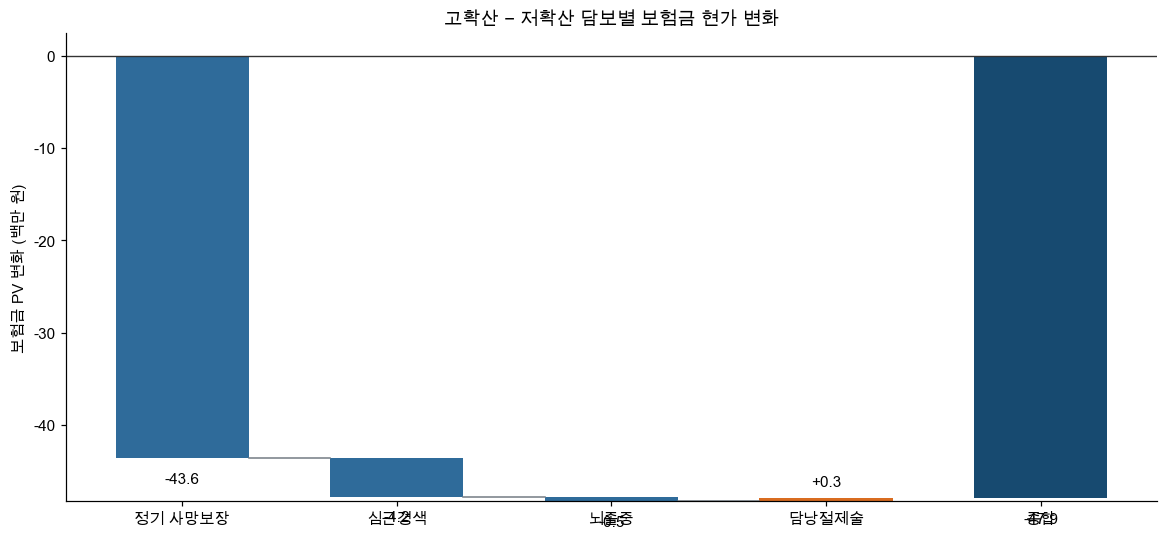

In [6]:
components = claim_df[claim_df['benefit_id'] != 'total'].copy()
values = components['claim_change_krw'].to_numpy() / 1e6
labels = components['benefit_name_ko'].replace({'비치명적 심근경색':'심근경색','비치명적 뇌졸중':'뇌졸중'}).tolist()
cumulative = np.r_[0, np.cumsum(values)]

fig, ax = plt.subplots(figsize=(10.5, 4.8), layout='constrained')
for i, value in enumerate(values):
    bottom = min(cumulative[i], cumulative[i+1])
    color = BLUE if value < 0 else ORANGE
    ax.bar(i, abs(value), bottom=bottom, color=color, width=.62)
    if i < len(values)-1:
        ax.plot([i+.31, i+1-.31], [cumulative[i+1], cumulative[i+1]], color=GREY, lw=1)
    ax.text(i, bottom - 1.5 if value < 0 else bottom + abs(value) + 1.0,
            f'{value:+,.1f}', ha='center', va='top' if value < 0 else 'bottom', weight='bold')
ax.bar(len(values), abs(cumulative[-1]), bottom=min(0, cumulative[-1]), color='#174A70', width=.62)
ax.text(len(values), cumulative[-1]-1.5, f'{cumulative[-1]:+,.1f}', ha='center', va='top', weight='bold')
ax.axhline(0, color='#333333', lw=.9)
ax.set(xticks=range(len(values)+1), xticklabels=labels+['종합'],
       ylabel='보험금 PV 변화 (백만 원)', title='고확산 − 저확산 담보별 보험금 현가 변화')
plt.show()

In [7]:
total_change = base['total_claim_change_krw']
display(Markdown(
    f"사망보장 감소가 전체 효과의 대부분을 차지한다. 담낭절제술은 증가하지만, "
    f"네 담보 합계는 보험금 **{abs(total_change)/1e6:,.2f}백만 원 감소**이며 "
    f"보험사 영향의 부호로는 **{base['insurer_impact_krw']/1e6:,.2f}백만 원**이다. "
    f"계약 1건당 보험금 변화는 **{base['per_policy_claim_change_krw']:+,.0f}원**이다."
))

사망보장 감소가 전체 효과의 대부분을 차지한다. 담낭절제술은 증가하지만, 네 담보 합계는 보험금 **47.91백만 원 감소**이며 보험사 영향의 부호로는 **47.91백만 원**이다. 계약 1건당 보험금 변화는 **-47,910원**이다.

### 6-2. 저확산·고확산 보험금 현가

사망보장과 종합은 억 원, 나머지 담보는 백만 원 패널로 분리해 규모 차이로 인한 가림을 줄였다.

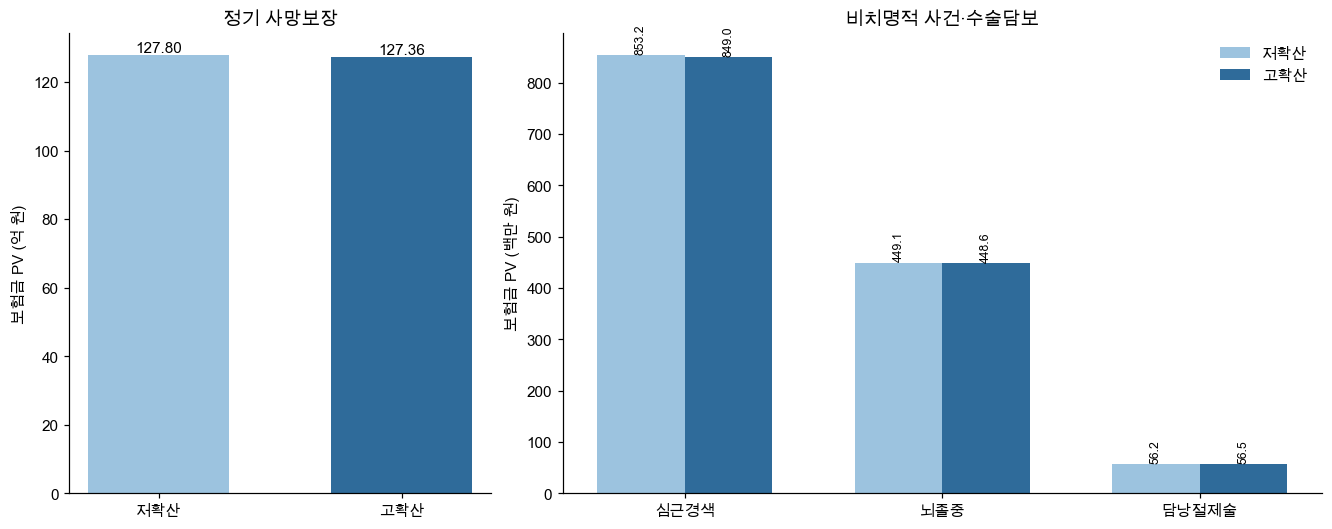

In [8]:
non_total = claim_df[claim_df['benefit_id'] != 'total'].copy()
death = non_total[non_total['benefit_id'] == 'death']
other = non_total[non_total['benefit_id'] != 'death']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout='constrained', gridspec_kw={'width_ratios':[1,1.8]})

x = np.arange(2)
death_vals = [death.iloc[0]['low_market_pv_krw']/1e8, death.iloc[0]['high_market_pv_krw']/1e8]
bars = axes[0].bar(x, death_vals, color=[LIGHT_BLUE, BLUE], width=.58)
axes[0].set(xticks=x, xticklabels=['저확산','고확산'], ylabel='보험금 PV (억 원)', title='정기 사망보장')
for b, v in zip(bars, death_vals): axes[0].text(b.get_x()+b.get_width()/2, v+.8, f'{v:,.2f}', ha='center', weight='bold')

labels = other['benefit_name_ko'].replace({'비치명적 심근경색':'심근경색','비치명적 뇌졸중':'뇌졸중'}).tolist()
x = np.arange(len(other)); w=.34
low = other['low_market_pv_krw'].to_numpy()/1e6; high = other['high_market_pv_krw'].to_numpy()/1e6
b1=axes[1].bar(x-w/2, low, w, label='저확산', color=LIGHT_BLUE)
b2=axes[1].bar(x+w/2, high, w, label='고확산', color=BLUE)
axes[1].set(xticks=x, xticklabels=labels, ylabel='보험금 PV (백만 원)', title='비치명적 사건·수술담보')
axes[1].legend(frameon=False)
for bars in (b1,b2):
    for b in bars: axes[1].text(b.get_x()+b.get_width()/2,b.get_height()+8,f'{b.get_height():,.1f}',ha='center',fontsize=8,rotation=90)
plt.show()

In [9]:
display(Markdown(
    "고확산에서는 사망·심근경색·뇌졸중 보험금 PV가 감소하고 담낭절제술 보험금 PV는 증가한다. "
    "그래프의 절대 수준은 담보금액과 기초위험을 함께 반영하므로 치료효과 크기만의 비교는 아니다."
))

고확산에서는 사망·심근경색·뇌졸중 보험금 PV가 감소하고 담낭절제술 보험금 PV는 증가한다. 그래프의 절대 수준은 담보금액과 기초위험을 함께 반영하므로 치료효과 크기만의 비교는 아니다.

### 6-3. 담낭수술 증가의 상쇄 비율

담낭절제술 보험금 증가를 사망·심혈관 보험금 감소 합계로 나눈다.

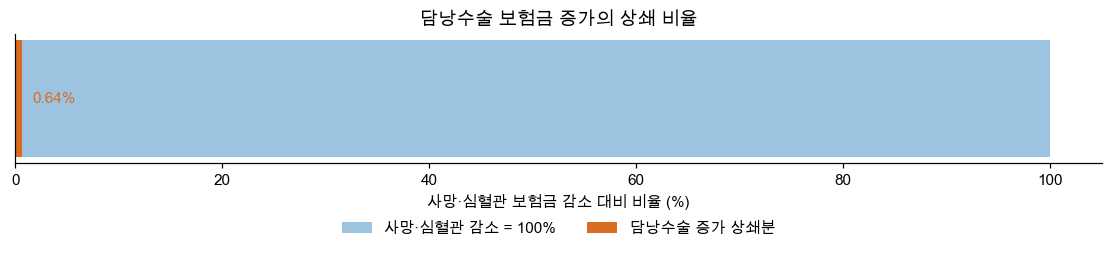

기준 SELECT 담석증 위험에서 상쇄 비율은 **0.64%**다. 이는 시장 확산 조건부 결과이며 특약 귀속효과가 아니다.

In [10]:
offset_pct = base['gallbladder_offset_ratio'] * 100
fig, ax = plt.subplots(figsize=(10, 2.1), layout='constrained')
ax.barh([0], [100], color=LIGHT_BLUE, height=.42, label='사망·심혈관 감소 = 100%')
ax.barh([0], [offset_pct], color=ORANGE, height=.42, label='담낭수술 증가 상쇄분')
ax.text(offset_pct + 1.0, 0, f'{offset_pct:.2f}%', va='center', weight='bold', color=ORANGE)
ax.set(xlim=(0,105), yticks=[], xlabel='사망·심혈관 보험금 감소 대비 비율 (%)', title='담낭수술 보험금 증가의 상쇄 비율')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(.5,-.35), ncol=2)
plt.show()
display(Markdown(f"기준 SELECT 담석증 위험에서 상쇄 비율은 **{offset_pct:.2f}%**다. 이는 시장 확산 조건부 결과이며 특약 귀속효과가 아니다."))

## 7. 일원 민감도

보고 구간, 효과기간, 노출방식, 시작률과 기초위험을 바꾼 조건부 범위다. 통계적 신뢰구간이나 발생확률로 해석하지 않는다.

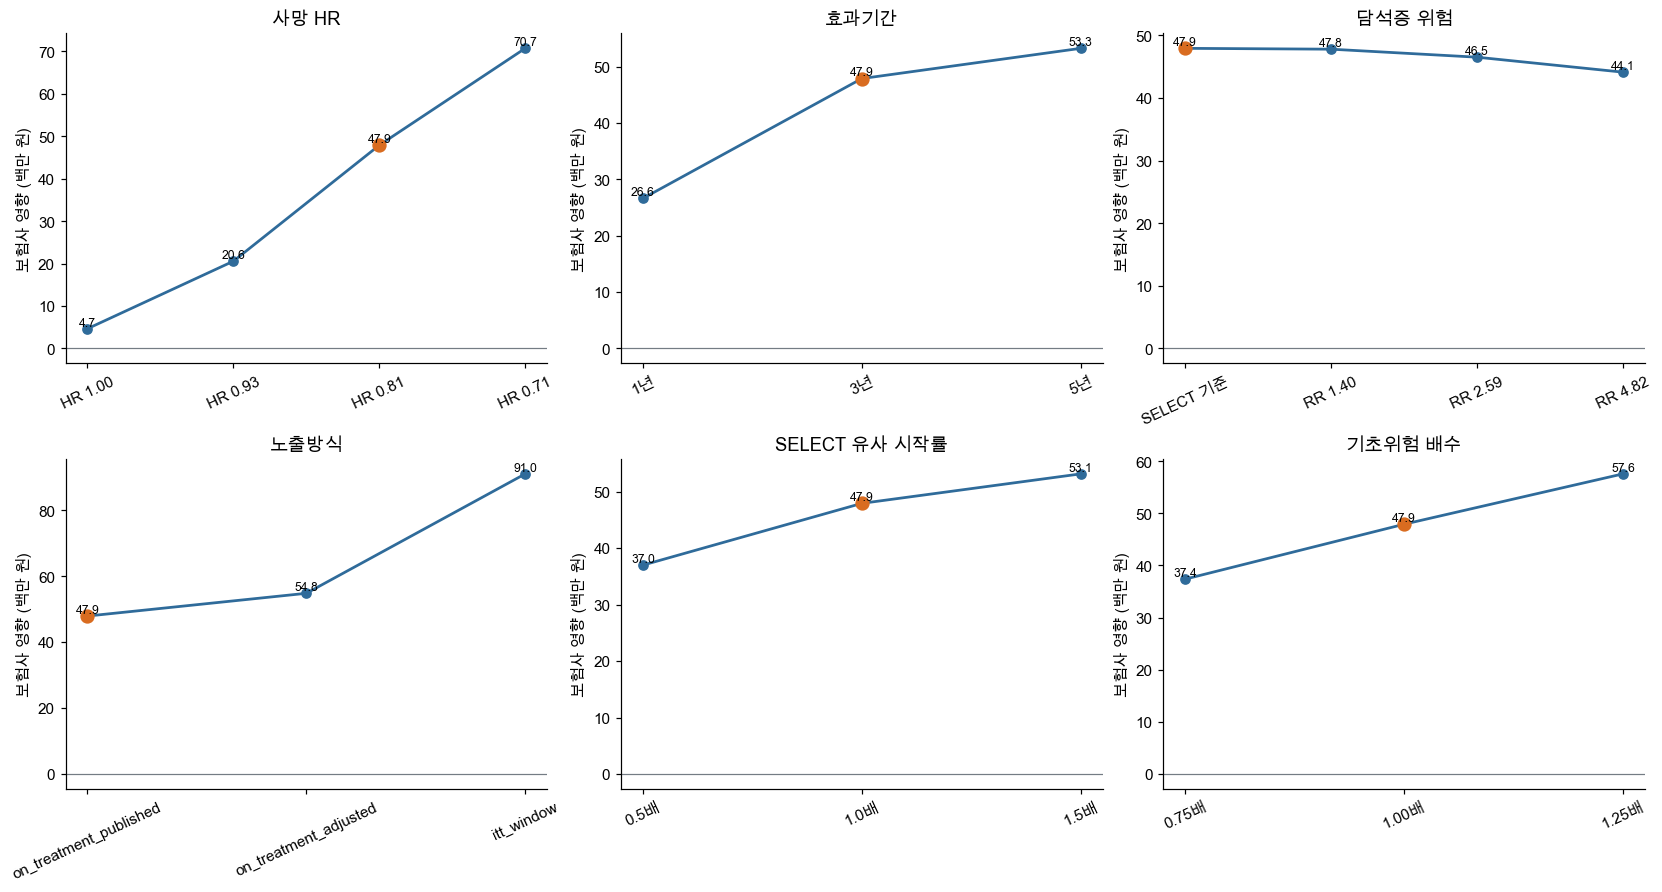

In [11]:
plot_specs = [
    ('death_hr','사망 HR'), ('benefit_effect_years','효과기간'),
    ('gallstone_rr','담석증 위험'), ('exposure_method','노출방식'),
    ('select_relative_start_multiplier','SELECT 유사 시작률'),
    ('all_base_risk_multiplier','기초위험 배수'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for ax, (variable, title) in zip(axes.flat, plot_specs):
    sub = sens_df[sens_df['variable'] == variable].copy()
    y = sub['insurer_impact_krw'].to_numpy()/1e6
    x = np.arange(len(sub))
    ax.plot(x, y, color=BLUE, marker='o', lw=1.8)
    base_index = np.argmin(np.abs(y - base['insurer_impact_krw']/1e6))
    ax.scatter([base_index], [y[base_index]], color=ORANGE, s=70, zorder=3, label='기준에 가장 가까운 설정')
    ax.axhline(0, color=GREY, lw=.8)
    ax.set(xticks=x, xticklabels=sub['display'], title=title, ylabel='보험사 영향 (백만 원)')
    ax.tick_params(axis='x', rotation=25)
    for xi, yi in zip(x,y): ax.text(xi, yi, f'{yi:,.1f}', ha='center', va='bottom', fontsize=8)
plt.show()

In [12]:
sens_min = sens_df.loc[sens_df['insurer_impact_krw'].idxmin()]
sens_max = sens_df.loc[sens_df['insurer_impact_krw'].idxmax()]
display(Markdown(
    f"일원 민감도에서 보험사 영향은 **{sens_min['insurer_impact_krw']/1e6:,.2f}~"
    f"{sens_max['insurer_impact_krw']/1e6:,.2f}백만 원**이다. 5년 효과는 SELECT 추적기간을 넘는 외삽이며, "
    "투약비율 보정형도 직접 관찰된 투약 중 효과가 아니다."
))

일원 민감도에서 보험사 영향은 **4.67~91.01백만 원**이다. 5년 효과는 SELECT 추적기간을 넘는 외삽이며, 투약비율 보정형도 직접 관찰된 투약 중 효과가 아니다.

## 8. 결합 시나리오

유리·기준·불리·무효과 조합에는 발생확률을 부여하지 않았다.

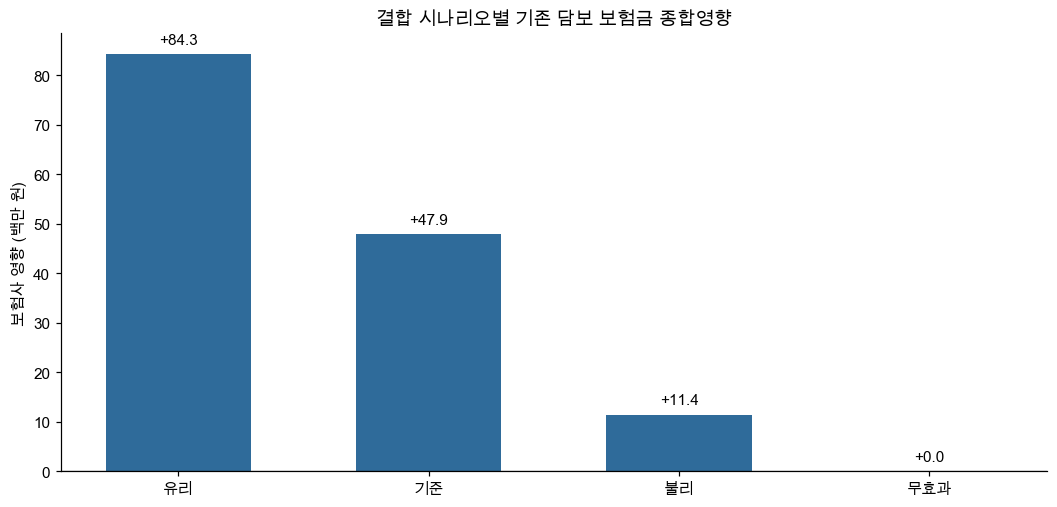

,display_name_ko,death_claim_change_krw,mi_claim_change_krw,stroke_claim_change_krw,gallbladder_claim_change_krw,insurer_impact_krw
0,유리,"-75,502,115","-6,497,296","-2,300,004","+11,836","+84,287,578"
1,기준,"-43,571,696","-4,169,987","-477,162","+309,106","+47,909,740"
2,불리,"-16,030,993","-2,263,880","+41,217","+6,882,843","+11,370,812"
3,무효과,+0,-0,+0,-0,+0


In [13]:
fig, ax = plt.subplots(figsize=(9.5, 4.5), layout='constrained')
vals = combined_df['insurer_impact_krw'].to_numpy()/1e6
colors = [BLUE if v >= 0 else ORANGE for v in vals]
bars = ax.bar(combined_df['display_name_ko'], vals, color=colors, width=.58)
ax.axhline(0, color='#333333', lw=.8)
for b,v in zip(bars,vals):
    ax.text(b.get_x()+b.get_width()/2, v+(1.5 if v>=0 else -1.5), f'{v:+,.1f}', ha='center', va='bottom' if v>=0 else 'top', weight='bold')
ax.set(ylabel='보험사 영향 (백만 원)', title='결합 시나리오별 기존 담보 보험금 종합영향')
plt.show()
combined_view = combined_df[['display_name_ko','death_claim_change_krw','mi_claim_change_krw','stroke_claim_change_krw','gallbladder_claim_change_krw','insurer_impact_krw']]
display(combined_view.style.format({column: '{:+,.0f}' for column in combined_view.columns if column != 'display_name_ko'}))

In [14]:
adverse = combined_df.loc[combined_df['scenario_id'] == 'adverse'].iloc[0]
display(Markdown(
    f"불리 조합에서도 기준 입력상 보험금 합계는 **{adverse['insurer_impact_krw']/1e6:,.2f}백만 원 감소 방향**이다. "
    "다만 이는 시나리오 확률이나 실제 보험사 손익을 뜻하지 않으며, 무효과 조합은 수치 오차 수준의 0이다."
))

불리 조합에서도 기준 입력상 보험금 합계는 **11.37백만 원 감소 방향**이다. 다만 이는 시나리오 확률이나 실제 보험사 손익을 뜻하지 않으며, 무효과 조합은 수치 오차 수준의 0이다.

## 9. 개별 분석과 공통모형 대조

In [15]:
legacy_df = pd.read_csv(ROOT/'outputs/existing_claims_impact/legacy_notebook_reference_comparison.csv')
display(legacy_df.style.format({
    'legacy_claim_change_krw':'{:+,.0f}',
    'common_model_claim_change_krw':'{:+,.0f}',
    'difference_common_minus_legacy_krw':'{:+,.0f}',
}))

,benefit_id,legacy_notebook,legacy_claim_change_krw,common_model_claim_change_krw,difference_common_minus_legacy_krw,main_differences
0,death,notebooks/impact/01_위고비_사망보장_국내연구.ipynb,"-96,961,864","-43,571,696","+53,390,168","월 모형, 저·고확산 연 시작률 1%·3%, 할인율 3%, 치료 지속·중단·재개 미적용"
1,mi,notebooks/impact/02_위고비_심혈관보험금_국내연구.ipynb,"-9,706,245","-4,169,987","+5,536,258","월 모형, 개별 노트북 시작경로와 노출 정의, 할인율 3%"
2,stroke,notebooks/impact/02_위고비_심혈관보험금_국내연구.ipynb,"-1,302,874","-477,162","+825,712","월 모형, 개별 노트북 시작경로와 노출 정의, 할인율 3%"
3,gallbladder,notebooks/impact/03_위고비_담낭수술보험금_국내연구.ipynb,"+6,119,385","+309,106","-5,810,279","Safwan RR 2.59 기준, 개별 시작·치료노출 경로; 공통모형 기준은 SELECT 1.4% 대 1.1%"


기존 값을 강제로 맞추지 않았다. 공통모형은 2.75% 할인, 전용 일별 시작률, 지속·중단·재개, 생존과 첫 지급 이력을 함께 적용한다. 01·02번은 월별 1%·3% 시작률과 3% 할인, 03번은 Safwan RR 2.59가 기준이어서 직접 합산 대상이 아니다.

## 10. 해석과 한계

- 담보 보유율 100%와 시작률은 실제 포트폴리오 추정이 아니라 조건부 연구 가정이다.
- SELECT 평균위험과 효과를 10년으로 외삽하며 연령 증가, 사건 후 사망위험 증가, 수술 대기와 해지를 반영하지 않는다.
- 기준 노출형은 ITT 효과를 치료 중 날짜에만 적용해 임상효과를 이중으로 약화할 수 있다.
- 일별 기대상태의 주변분포를 추적하므로 개인별 사건 상관과 같은 날 사건·사망의 정확한 결합분포를 모형화하지 않는다.
- 보험료, 준비금, 세금, 투자손익과 자본비용이 없어 결과를 보험사 손익으로 부르지 않는다.

## 11. 계산 검증

In [16]:
validation_df = pd.DataFrame(analysis['validation']['checks'])
display(validation_df)
assert analysis['validation']['status'] == 'PASS'
display(Markdown(f"**검증 {analysis['validation']['checks_passed']}/{analysis['validation']['checks_total']} 통과**"))

,check,passed,detail
0,high_market_has_more_first_starts,True,
1,high_market_has_more_treatment_exposure,True,
2,all_effect_multipliers_one_produce_zero_change,True,
3,equal_gallstone_risk_produces_zero_extra_surge...,True,
4,death_removed_and_mass_conserved,True,
5,nonfatal_paid_lives_can_start_later,True,
6,nonfatal_benefits_are_independent_and_remain_p...,True,담보별 미청구 상태를 별도 추적하므로 서로 다른 비치명적 담보 지급을 허용
7,each_nonfatal_benefit_paid_at_most_once,True,
8,double_benefit_doubles_claim_change,True,
9,half_holding_rate_halves_claim_change,True,


**검증 15/15 통과**

## 12. 이후 특약 손익과의 연결

시장 저확산→고확산 결과 전체를 약제비 특약에 귀속하면 안 된다. 특약 연결 단계에서는 `특약 없음 A → 특약 있음 A+B`의 추가 시작경로로 네 담보의 현가 변화분을 다시 산출하고, 담보별 실제 보유·유효 비중을 적용한다. 그 결과도 특약 보험료 수지와 구분해 보고한 뒤 필요한 의사결정 표에서만 나란히 제시한다.